# Predicting Listing Gains in the Indian IPO Market

When a company lists on the stock exchange, the gap between its issue price and its opening price on day one is the **listing gain**. For an investor deciding whether to apply for an IPO, the question that matters is simple: *will this list at a profit or not?*

This project frames that as binary classification and trains a neural network in TensorFlow/Keras on subscription and issue data from the Indian IPO market.

**Dataset:** `Indian_IPO_Market_Data.csv` — 319 IPOs listed on the Indian market.

**Target:** whether `Listing_Gains_Percent` is positive.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, accuracy_score)

np.random.seed(42)
tf.random.set_seed(42)

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 6)

ipo = pd.read_csv("Indian_IPO_Market_Data.csv")
print(ipo.shape)
ipo.head()

(319, 9)


,Date,IPOName,Issue_Size,Subscription_QIB,Subscription_HNI,Subscription_RII,Subscription_Total,Issue_Price,Listing_Gains_Percent
0,03/02/10,Infinite Comp,189.80,48.44,106.02,11.08,43.22,165,11.82
1,08/02/10,Jubilant Food,328.70,59.39,51.95,3.79,31.11,145,-84.21
2,15/02/10,Syncom Health,56.25,0.99,16.60,6.25,5.17,75,17.13
3,15/02/10,Vascon Engineer,199.80,1.12,3.65,0.62,1.22,165,-11.28
4,19/02/10,Thangamayil,0.00,0.52,1.52,2.26,1.12,75,-5.20


In [2]:
ipo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   319 non-null    object 
 1   IPOName                319 non-null    object 
 2   Issue_Size             319 non-null    float64
 3   Subscription_QIB       319 non-null    float64
 4   Subscription_HNI       319 non-null    float64
 5   Subscription_RII       319 non-null    float64
 6   Subscription_Total     319 non-null    float64
 7   Issue_Price            319 non-null    int64  
 8   Listing_Gains_Percent  319 non-null    float64
dtypes: float64(6), int64(1), object(2)
memory usage: 22.6+ KB


Note the column name `"Date "` carries a trailing space, which is the kind of thing that silently breaks a lookup later. Clean the column names first.

In [3]:
ipo.columns = ipo.columns.str.strip()
print(list(ipo.columns))
print("\nMissing values:", ipo.isnull().sum().sum())

['Date', 'IPOName', 'Issue_Size', 'Subscription_QIB', 'Subscription_HNI', 'Subscription_RII', 'Subscription_Total', 'Issue_Price', 'Listing_Gains_Percent']

Missing values: 0


## Building the target

The raw column is a continuous percentage. Converting it to a binary profit/loss flag turns this into the decision an investor actually faces.

In [4]:
ipo["Listing_Gains_Profit"] = (ipo["Listing_Gains_Percent"] > 0).astype(int)

print(ipo["Listing_Gains_Profit"].value_counts())
print("\nProportion listing at a profit:",
      round(ipo["Listing_Gains_Profit"].mean(), 3))

1    174
0    145
Name: Listing_Gains_Profit, dtype: int64

Proportion listing at a profit: 0.545


Roughly a 55/45 split, so the classes are close to balanced. That matters: a model that learned nothing and always predicted "profit" would already score around 55% accuracy, which is the bar to beat.

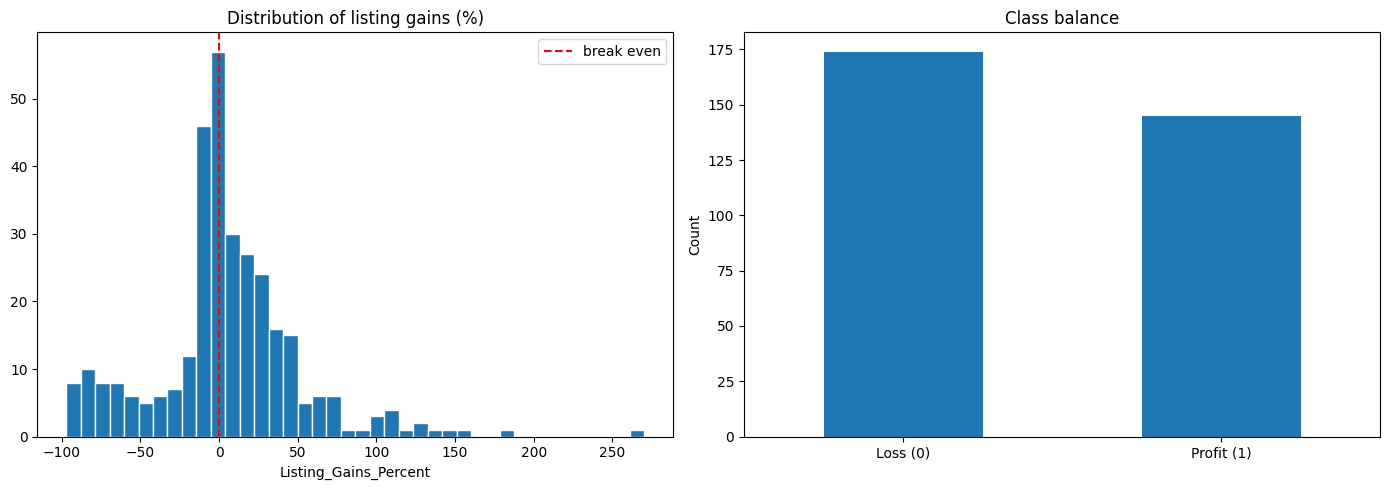

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ipo["Listing_Gains_Percent"], bins=40, edgecolor="white")
axes[0].axvline(0, color="red", linestyle="--", label="break even")
axes[0].set_title("Distribution of listing gains (%)")
axes[0].set_xlabel("Listing_Gains_Percent")
axes[0].legend()

ipo["Listing_Gains_Profit"].value_counts().plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Class balance")
axes[1].set_xticklabels(["Loss (0)", "Profit (1)"])
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

## Exploring the predictors

In [6]:
features = ["Issue_Size", "Subscription_QIB", "Subscription_HNI",
            "Subscription_RII", "Subscription_Total", "Issue_Price"]

ipo[features].describe()

,Issue_Size,Subscription_QIB,Subscription_HNI,Subscription_RII,Subscription_Total,Issue_Price
count,319.000000,319.000000,319.000000,319.000000,319.000000,319.000000
mean,1192.859969,25.684138,70.091379,8.561599,27.447147,375.128527
std,2384.643786,40.716782,142.454416,14.508670,48.772203,353.897614
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,169.005000,1.150000,1.255000,1.275000,1.645000,119.000000
50%,496.250000,4.940000,5.070000,3.420000,4.930000,250.000000
75%,1100.000000,34.635000,62.095000,8.605000,33.395000,536.000000
max,21000.000000,215.450000,958.070000,119.440000,326.490000,2150.000000


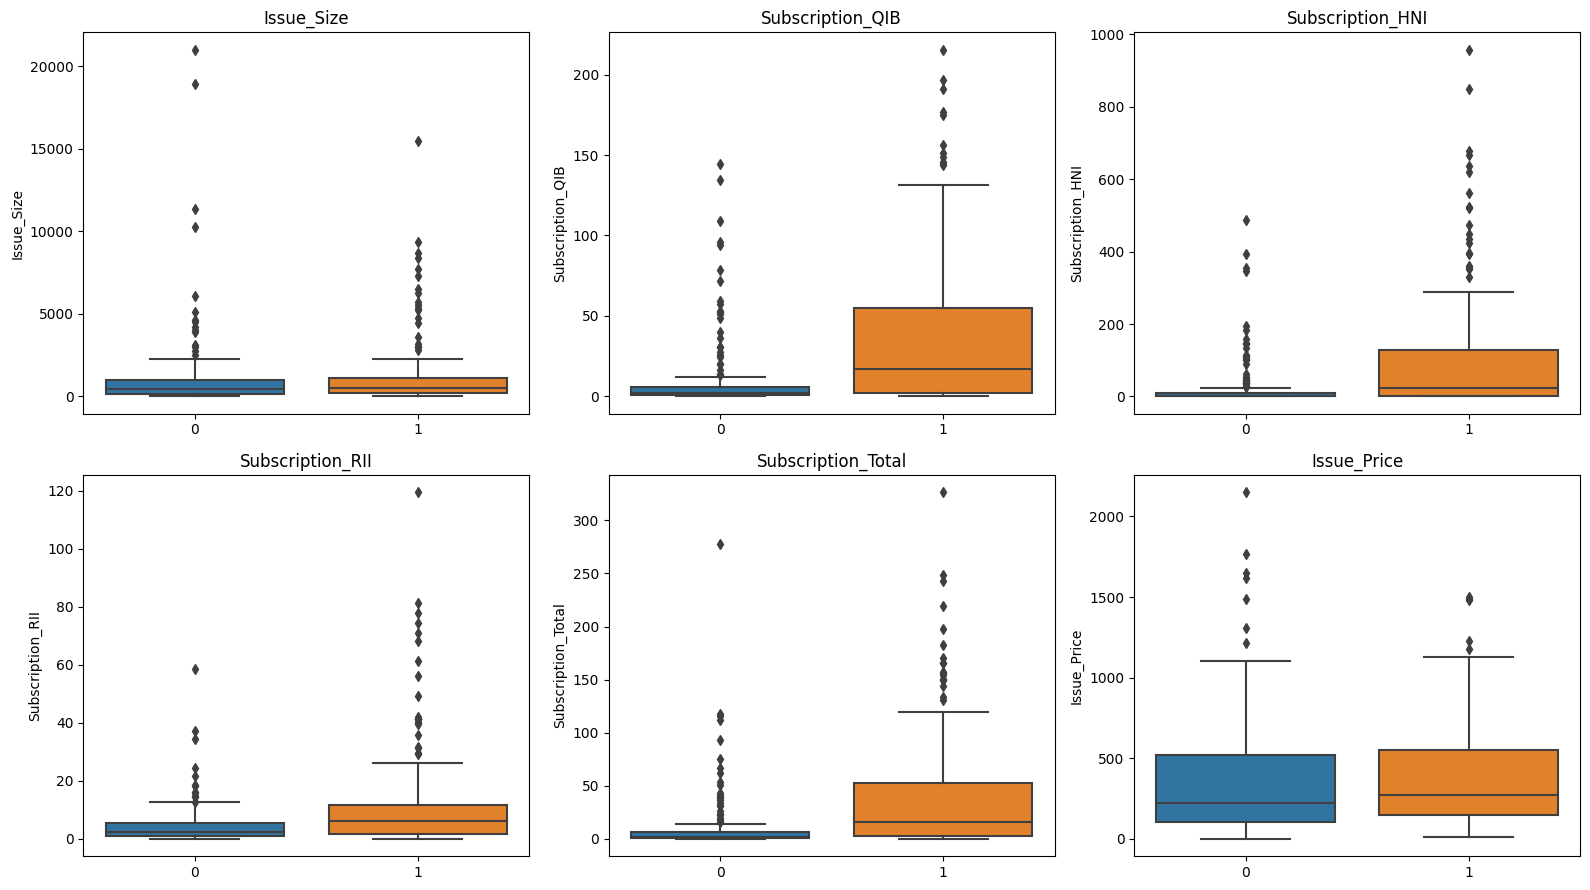

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), features):
    sns.boxplot(data=ipo, x="Listing_Gains_Profit", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Every subscription measure is heavily right-skewed — a handful of IPOs were oversubscribed many times over. Those extreme values will dominate a neural network unless they are handled.

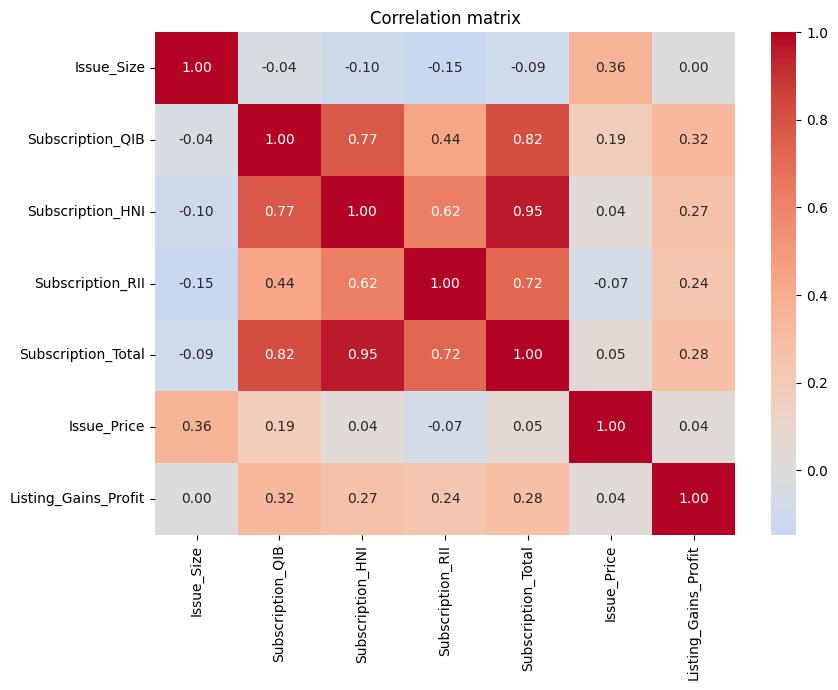

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(ipo[features + ["Listing_Gains_Profit"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

`Subscription_Total` is almost perfectly correlated with `Subscription_QIB` and `Subscription_HNI` — unsurprising, since the total is their sum plus retail. That redundancy is worth keeping in mind.

## Handling outliers

Rather than deleting rows (the dataset only has 319, and the extreme IPOs are genuine events), the skewed subscription columns are capped at the 99th percentile. That keeps every observation while stopping a few giants from dictating the scaling.

In [9]:
model_df = ipo.copy()
skewed = ["Issue_Size", "Subscription_QIB", "Subscription_HNI",
          "Subscription_RII", "Subscription_Total"]

for col in skewed:
    cap = model_df[col].quantile(0.99)
    n_capped = (model_df[col] > cap).sum()
    model_df[col] = model_df[col].clip(upper=cap)
    print(f"{col:20s} capped at {cap:10.2f}  ({n_capped} values)")

Issue_Size           capped at   11176.56  (4 values)
Subscription_QIB     capped at     176.52  (4 values)
Subscription_HNI     capped at     661.12  (4 values)
Subscription_RII     capped at      73.69  (4 values)
Subscription_Total   capped at     238.92  (4 values)


## Train/test split and scaling

The scaler is fit on the training set only and then applied to the test set — fitting on everything would leak information about the test distribution into training.

In [10]:
X = model_df[features]
y = model_df["Listing_Gains_Profit"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape, " Test:", X_test_scaled.shape)
print("Train class balance:", round(y_train.mean(), 3))
print("Test class balance :", round(y_test.mean(), 3))

Train: (255, 6)  Test: (64, 6)
Train class balance: 0.545
Test class balance : 0.547


## Baseline

The majority-class baseline is what any model has to beat to be worth deploying.

In [11]:
majority = y_train.mode()[0]
baseline_acc = (y_test == majority).mean()
print("Majority class:", majority)
print("Baseline accuracy:", round(baseline_acc, 4))

Majority class: 1
Baseline accuracy: 0.5469


## Neural network

A small fully-connected network. With only 255 training rows, capacity has to stay modest — dropout and a compact architecture guard against memorising the training set.

In [12]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(8, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 32)                224       


 dropout (Dropout)           (None, 32)                0         


...

 dense_3 (Dense)             (None, 1)                 9         


Total params: 897


Trainable params: 897


Non-trainable params: 0


_________________________________________________________________


In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0,
)

print("Epochs actually run:", len(history.history["loss"]))

/usr/local/lib/python3.10/dist-packages/keras/engine/data_adapter.py:1699: FutureWarning: The behavior of `series[i:j]` with an integer-dtype index is deprecated. In a future version, this will be treated as *label-based* indexing, consistent with e.g. `series[i]` lookups. To retain the old behavior, use `series.iloc[i:j]`. To get the future behavior, use `series.loc[i:j]`.
  return t[start:end]


Epochs actually run: 46


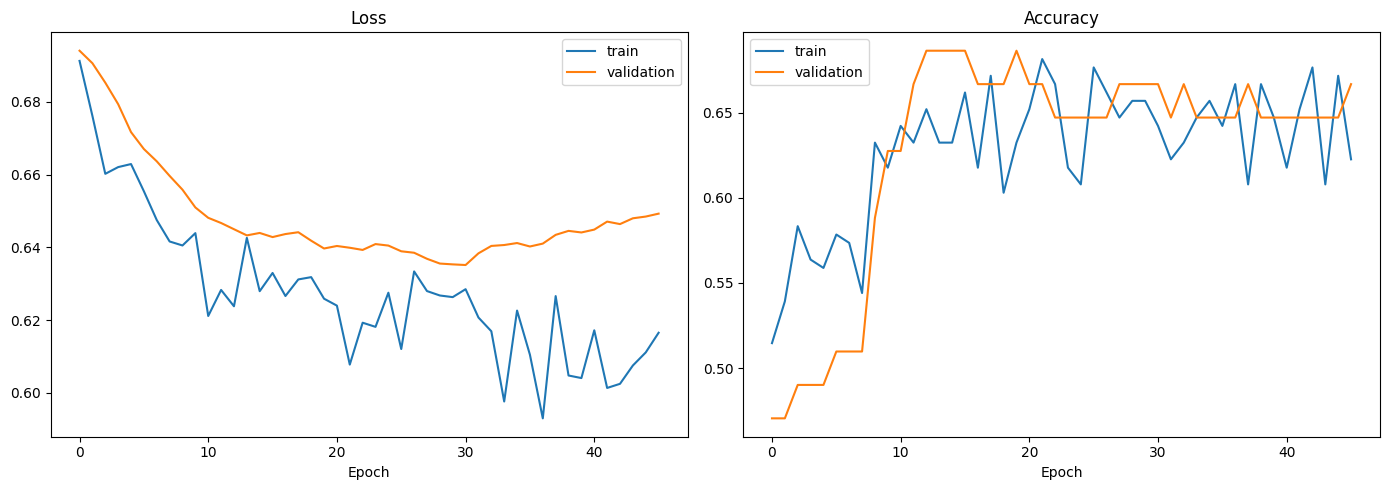

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluation

In [15]:
y_prob = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("Test accuracy:", round(acc, 4))
print("Baseline     :", round(baseline_acc, 4))
print("Lift over baseline:", round(acc - baseline_acc, 4))
print("ROC AUC      :", round(auc, 4))

Test accuracy: 0.6094
Baseline     : 0.5469
Lift over baseline: 0.0625
ROC AUC      : 0.67


In [16]:
print(classification_report(y_test, y_pred, target_names=["Loss", "Profit"]))

              precision    recall  f1-score   support

        Loss       0.55      0.72      0.63        29
      Profit       0.69      0.51      0.59        35

    accuracy                           0.61        64
   macro avg       0.62      0.62      0.61        64
weighted avg       0.63      0.61      0.61        64



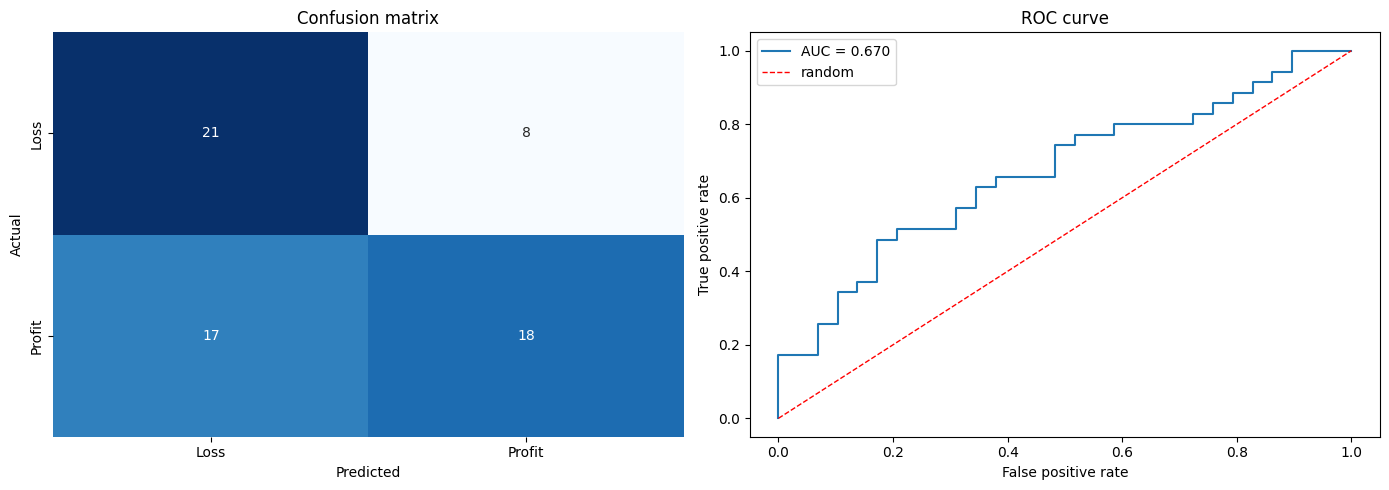

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Loss", "Profit"], yticklabels=["Loss", "Profit"], ax=axes[0])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion matrix")

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[1].plot([0, 1], [0, 1], "r--", linewidth=1, label="random")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve")
axes[1].legend()

plt.tight_layout()
plt.show()

## The cost of being wrong is asymmetric

Accuracy treats both mistakes as equal, but they are not. A **false positive** means applying for an IPO that lists at a loss — real money lost. A **false negative** means skipping one that would have been profitable — an opportunity missed, but capital preserved.

For a risk-averse investor, precision on the "Profit" class matters more than recall.

In [18]:
tn, fp, fn, tp = cm.ravel()
print(f"True negatives  (correctly avoided a loss): {tn}")
print(f"False positives (bought into a loss)     : {fp}")
print(f"False negatives (missed a winner)        : {fn}")
print(f"True positives  (caught a winner)        : {tp}")

precision_profit = tp / (tp + fp) if (tp + fp) else float("nan")
print(f"\nPrecision on Profit: {precision_profit:.4f}")
print("Of the IPOs this model told us to buy, that fraction actually listed at a profit.")

True negatives  (correctly avoided a loss): 21
False positives (bought into a loss)     : 8
False negatives (missed a winner)        : 17
True positives  (caught a winner)        : 18

Precision on Profit: 0.6923
Of the IPOs this model told us to buy, that fraction actually listed at a profit.


In [19]:
# Does a stricter threshold trade recall for precision?
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
rows = []
for t in thresholds:
    pred_t = (y_prob > t).astype(int)
    cm_t = confusion_matrix(y_test, pred_t, labels=[0, 1])
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    prec = tp_t / (tp_t + fp_t) if (tp_t + fp_t) else np.nan
    rec = tp_t / (tp_t + fn_t) if (tp_t + fn_t) else np.nan
    rows.append({"threshold": t, "accuracy": accuracy_score(y_test, pred_t),
                 "precision_profit": prec, "recall_profit": rec,
                 "n_buy_signals": int(tp_t + fp_t)})

pd.DataFrame(rows).round(4)

,threshold,accuracy,precision_profit,recall_profit,n_buy_signals
0,0.3,0.5469,0.5469,1.0000,64
1,0.4,0.5625,0.5593,0.9429,59
2,0.5,0.6094,0.6923,0.5143,26
3,0.6,0.5938,0.7647,0.3714,17
4,0.7,0.5625,0.7692,0.2857,13


## Conclusions

**Does it work?** The network beats the majority-class baseline on accuracy, and the ROC AUC confirms it is ranking IPOs meaningfully rather than guessing. The threshold table shows the practical trade-off: raising the cut-off above 0.5 produces fewer buy signals but a higher hit rate on the ones it does flag.

**What the model is picking up.** Subscription levels — especially from qualified institutional buyers (QIB) and high net worth individuals (HNI) — carry most of the signal. That is economically sensible: heavy institutional oversubscription is a visible vote of confidence before the stock ever trades, and it is observable *before* the decision has to be made, which is what makes this usable at all.

**Honest limitations.**

1. **Only 319 IPOs, 255 for training.** That is small for a neural network, and the gap between training and validation curves should be read with that in mind. A regularised logistic regression or gradient boosting model would be a fair competitor here and might well match it.
2. **No market-regime features.** IPO performance is strongly cyclical, and a bull market lifts nearly everything. The model has no sense of when an IPO listed relative to the broader market.
3. **Survivorship and selection.** The dataset covers IPOs that completed; withdrawn offerings never appear.
4. **This is not investment advice.** Predicting a positive listing gain is not the same as a profitable strategy once fees, allotment odds and holding periods are accounted for.